## Part A — Dataset and graph construction 

In [1]:
# ============================================================
# SECTION 0 — Imports and reproducibility
# ============================================================
import os
import random
import warnings
from collections import Counter
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm # matplotlib's colormap functionality
import seaborn as sns
import networkx as nx
import igraph as ig
import community as community_louvain #tentative community detection 
from scipy.stats import spearmanr # spearmanrank correlation

warnings.filterwarnings("ignore")

# reproducibility
GLOBAL_SEED = 42
random.seed(GLOBAL_SEED)
np.random.seed(GLOBAL_SEED)

# output folder
OUT = "outputs"
os.makedirs(OUT, exist_ok=True)

In [2]:
# ============================================================
# SECTION 1 — Load polblogs.gml
# ============================================================
GML_PATH = "polblogs.gml"

def load_graph(path=GML_PATH):
    """
    Load polblogs.gml.
    The raw file contains duplicate edges, so NetworkX's default simple-graph
    reader raises. We route through igraph, which silently collapses duplicates,
    and rebuild a NetworkX DiGraph with all node attributes preserved.
    """
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Missing {path}. Download polblogs.zip from "
            "https://public.websites.umich.edu/~mejn/netdata/ and unzip here."
        )
    try:
        return nx.read_gml(path, label="id")
    except nx.NetworkXError:
        # Duplicate edges: route through igraph
        g_ig = ig.Graph.Read_GML(path)
        g = nx.DiGraph()
        for v in g_ig.vs:
            attrs = {k: v[k] for k in v.attributes() if v[k] is not None}
            node_id = int(attrs.get("id", v.index))
            g.add_node(node_id, **attrs)
        for e in g_ig.es:
            s = int(g_ig.vs[e.source]["id"])
            t = int(g_ig.vs[e.target]["id"])
            g.add_edge(s, t)
        return g

G_raw = load_graph()

print("=== RAW GRAPH ===")
print(f"Nodes    : {G_raw.number_of_nodes()}")
print(f"Edges    : {G_raw.number_of_edges()}")
print(f"Directed : {G_raw.is_directed()}")
print(f"Sample node attrs: {list(G_raw.nodes(data=True))[0]}")

=== RAW GRAPH ===
Nodes    : 1490
Edges    : 19025
Directed : True
Sample node attrs: (1, {'id': 1.0, 'label': '100monkeystyping.com', 'value': 0.0, 'source': 'Blogarama'})


In [3]:
# ============================================================
# SECTION 2 — Preprocessing
# ============================================================
def preprocess(g):
    """
    Clean the raw graph and return (clean_graph, labels, log).
    Decisions:
      1. Cast id and value to int (they load as float from GML).
      2. Remove self-loops (a blog linking to itself carries no relational info).
      3. Collapse duplicate edges (already done at load time via igraph).
      4. Keep isolates — they are real labelled blogs needed for evaluation.
    """
    log = []
    g = g.copy()

    # 1) Cast node ids and 'value' to int
    mapping = {n: int(n) for n in g.nodes()}
    g = nx.relabel_nodes(g, mapping)
    for n in g.nodes():
        g.nodes[n]["value"] = int(g.nodes[n]["value"])
        g.nodes[n]["id"] = int(g.nodes[n]["id"])

    # Labels preserved separately (ground truth — used only in Part E)
    labels = {n: g.nodes[n]["value"] for n in g.nodes()}

    # 2) Remove self-loops
    before_e = g.number_of_edges()
    self_loops = list(nx.selfloop_edges(g))
    g.remove_edges_from(self_loops)
    log.append(("Remove self-loops", before_e, g.number_of_edges(), len(self_loops)))

    # 3) Duplicate edges: already collapsed at load time
    log.append(("Collapse duplicate edges (at load via igraph)",
                g.number_of_edges(), g.number_of_edges(), 0))

    # 4) Isolates — detect but keep
    isolates = list(nx.isolates(g))
    log.append(("Isolates detected (kept)", len(isolates), len(isolates), len(isolates)))

    return g, labels, log, isolates


G, LABELS, PREP_LOG, ISOLATES = preprocess(G_raw)

df_log = pd.DataFrame(
    PREP_LOG,
    columns=["Step", "Before", "After", "Removed/Detected"]
)
print("=== PREPROCESSING LOG ===")
display(df_log)
print(f"\nFinal analysis graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")

=== PREPROCESSING LOG ===


,Step,Before,After,Removed/Detected
0,Remove self-loops,19025,19022,3
1,Collapse duplicate edges (at load via igraph),19022,19022,0
2,Isolates detected (kept),266,266,266



Final analysis graph: 1490 nodes, 19022 edges


### Data dictionary

| Element | Meaning |
|---|---|
| **Node** | A political blog (weblog) |
| **Node `id`** | Unique integer identifier for the blog |
| **Node `label`** | Blog name / domain |
| **Node `value`** | Binary political orientation — **0 = liberal, 1 = conservative**. Ground truth; used ONLY in Part E evaluation. |
| **Node `source`** | Directory where the blog was listed (e.g., Blogarama) — auxiliary attribute, not used in analysis |
| **Edge** | A hyperlink from one blog to another |
| **Edge direction** | `source → target` means source blog links to target blog |
| **Edge weight** | None — unweighted |
| **Multi-edge** | No — duplicate edges collapsed at load time |
| **Self-loop** | No — removed during preprocessing |

### Graph model

- **Directed** — hyperlinks have a meaningful direction (who links to whom).
- **Unweighted** — a link is either present or absent; there is no strength value.
- **Simple** — at most one edge per ordered pair (duplicate edges collapsed).

In [4]:
# ============================================================
# SECTION 3 — Graph properties
# ============================================================
def graph_properties(g):
    n = g.number_of_nodes()
    m = g.number_of_edges()
    density = nx.density(g)

    wcc = list(nx.weakly_connected_components(g))
    scc = list(nx.strongly_connected_components(g))
    largest_wcc = max(wcc, key=len)

    props = {
        "Nodes": n,
        "Edges": m,
        "Density": round(density, 6),
        "# Weakly connected components (WCC)": len(wcc),
        "Largest WCC size": len(largest_wcc),
        "# Strongly connected components (SCC)": len(scc),
        "Largest SCC size": max(len(c) for c in scc),
    }
    return props, largest_wcc, wcc, scc


PROPS, LARGEST_WCC, WCC, SCC = graph_properties(G)

print("=== GRAPH PROPERTIES ===")
for k, v in PROPS.items():
    print(f"{k:40s}: {v}")

# Analysis subgraph: largest weakly connected component
G_WCC = G.subgraph(LARGEST_WCC).copy()
print(f"\nLargest WCC subgraph: {G_WCC.number_of_nodes()} nodes, {G_WCC.number_of_edges()} edges")

=== GRAPH PROPERTIES ===
Nodes                                   : 1490
Edges                                   : 19022
Density                                 : 0.008574
# Weakly connected components (WCC)     : 268
Largest WCC size                        : 1222
# Strongly connected components (SCC)   : 688
Largest SCC size                        : 793

Largest WCC subgraph: 1222 nodes, 19021 edges


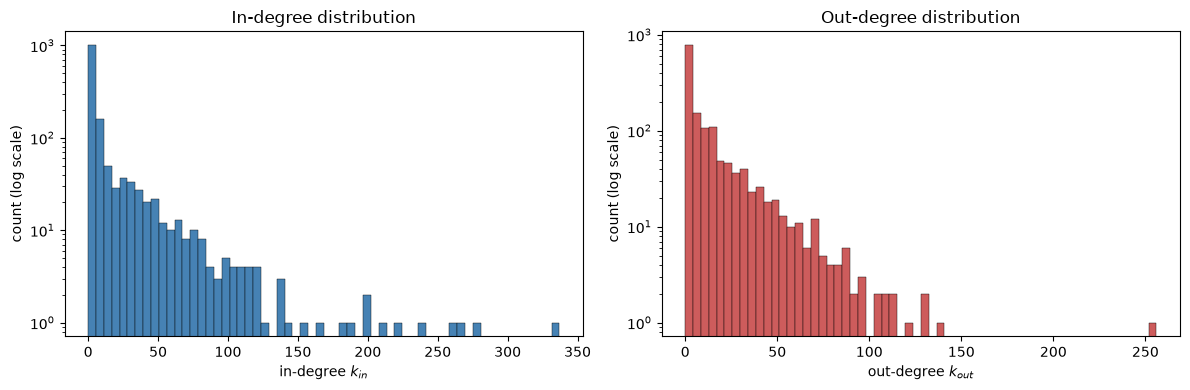

In-degree : mean=12.77, median=2.0, max=337
Out-degree: mean=12.77, median=4.0, max=256


In [5]:
# ============================================================
# SECTION 3b — Degree distribution figure
# ============================================================
in_deg  = [d for _, d in G.in_degree()]
out_deg = [d for _, d in G.out_degree()]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(in_deg, bins=60, color="steelblue", edgecolor="black", linewidth=0.3)
axes[0].set_title("In-degree distribution")
axes[0].set_xlabel("in-degree $k_{in}$")
axes[0].set_ylabel("count (log scale)")
axes[0].set_yscale("log")

axes[1].hist(out_deg, bins=60, color="indianred", edgecolor="black", linewidth=0.3)
axes[1].set_title("Out-degree distribution")
axes[1].set_xlabel("out-degree $k_{out}$")
axes[1].set_ylabel("count (log scale)")
axes[1].set_yscale("log")

plt.tight_layout()
plt.savefig(f"{OUT}/fig_degree_distribution.png", bbox_inches="tight")
plt.show()

print(f"In-degree : mean={np.mean(in_deg):.2f}, median={np.median(in_deg)}, max={max(in_deg)}")
print(f"Out-degree: mean={np.mean(out_deg):.2f}, median={np.median(out_deg)}, max={max(out_deg)}")

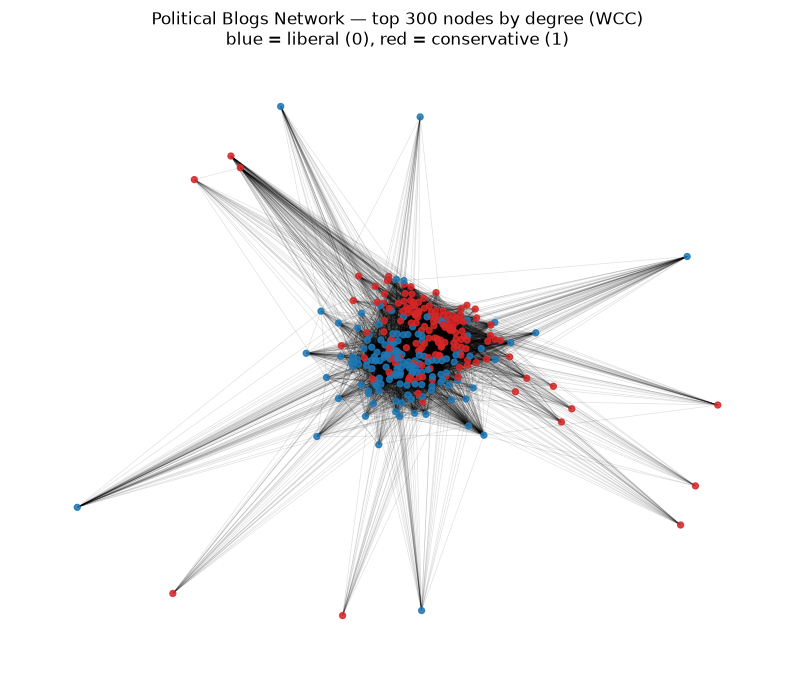

In [6]:
# ============================================================
# SECTION 3c — Readable network visualization (top-300 by degree)
# ============================================================
def visualize_top_nodes(g, top_k=300, labels=None, seed=GLOBAL_SEED,
                        fname="fig_network.png"):
    """Visualize the top-K nodes by total degree in the largest WCC."""
    wcc = max(nx.weakly_connected_components(g), key=len)
    sub = g.subgraph(wcc).copy()

    top_nodes = [n for n, _ in sorted(sub.degree, key=lambda x: x[1], reverse=True)[:top_k]]
    sub = sub.subgraph(top_nodes).copy()

    pos = nx.spring_layout(sub, seed=seed, k=0.15)
    colors = ["#1f77b4" if labels[n] == 0 else "#d62728" for n in sub.nodes()]

    plt.figure(figsize=(10, 8))
    nx.draw_networkx_nodes(sub, pos, node_color=colors, node_size=18, alpha=0.85)
    nx.draw_networkx_edges(sub, pos, alpha=0.12, arrows=False, width=0.5)
    plt.title(f"Political Blogs Network — top {top_k} nodes by degree (WCC)\n"
              "blue = liberal (0), red = conservative (1)")
    plt.axis("off")
    plt.savefig(f"{OUT}/{fname}", bbox_inches="tight")
    plt.show()


visualize_top_nodes(G, top_k=300, labels=LABELS)

### Part A — Interpretation

- The graph is **sparse** (density ≈ 0.0086), meaning that most blogs do not link directly to most other blogs.

- The in-degree and out-degree distributions are **strongly right-skewed with long tails**. The median in-degree is 2 and the median out-degree is 4, while the maximum in-degree and out-degree are 337 and 256, respectively. This indicates that most blogs have relatively few links, while a small number of highly connected blogs act as network hubs.

- The graph has **one dominant weakly connected component but is globally disconnected**. The largest weakly connected component (WCC) contains 1,222 of the 1,490 nodes (82%), while there are 268 WCCs in total. Thus, most blogs belong to one large connected network when edge direction is ignored, while the remaining nodes occur in smaller disconnected components.

- The directed structure is more fragmented in terms of mutual reachability. There are 688 strongly connected components (SCCs), and the largest SCC contains 793 nodes (53% of all nodes). This indicates that many blogs cannot mutually reach one another while respecting the direction of hyperlinks, which is relevant to understanding information flow through the network.

- The mean in-degree and mean out-degree are both **12.77**. This equality is expected in a directed graph because every directed edge contributes one unit to the out-degree of its source and one unit to the in-degree of its target.

- The label-colored network visualization provides an **exploratory view** of the relationship between political orientation and network structure. Some apparent clustering of the two orientations can be observed. However, the political-orientation labels are **not used to construct, seed, tune, or select communities**. They are preserved only for evaluation of the communities detected from the network structure.

- Because the graph is disconnected, **distance-based calculations require a clearly stated component and edge-direction convention**. For subsequent distance-based analysis, the largest WCC containing 1,222 nodes will be used, with the direction convention explicitly stated for each distance-based measure.

## Part B — Centrality Selection and Analysis

### Chosen centralities

**1. PageRank**
*Question:* Which blogs are most authoritative in the directed hyperlink
network, where influence received is diluted across each source's outgoing links?

*Why PageRank over alternatives:*
- Better than **in-degree** because it weighs links by the source's own authority
  (a link from a hub counts more than a link from a leaf).
- Better than **Katz** because PageRank is designed for directed graphs with
  highly skewed outgoing degrees and handles dangling nodes robustly via the
  damping factor.
- Better than **eigenvector centrality** because PageRank is well-defined on
  directed graphs even when the adjacency matrix is not irreducible.

**2. Betweenness centrality**
*Question:* Which blogs act as brokers or bridges between otherwise separated
regions of the network?

*Why betweenness over alternatives:*
- Directly operationalises brokerage: it counts how often a node lies on
  shortest paths between other pairs.
- **Closeness** measures reachability, not brokerage.
- **Eigenvector / Katz** measure importance by association, not by bridging.
- **PageRank** measures authority, not cross-community connection.

### Direction and component conventions

| Measure | Direction | Component | Justification |
|---|---|---|---|
| PageRank | Uses **incoming** links | Whole graph | Well-defined even on disconnected graphs |
| Betweenness | **Undirected** interpretation | **Largest WCC** (1222 nodes) | Distances are undefined across components; a hyperlink between two blogs is navigable in both directions in practice |

### Parameters

- **PageRank:** damping `α = 0.85`, tolerance `1e-6`, max iterations 100.
- **Betweenness:** normalized = True, unweighted.

Unreachable pairs contribute 0 to betweenness, which is the standard
NetworkX convention.

In [8]:
# ============================================================
# SECTION 4a — PageRank
# ============================================================
def compute_pagerank(g, alpha=0.85, tol=1e-6, max_iter=100):
    """
    PageRank with damping factor alpha.
    Uses incoming links (authority = links received).
    Dangling nodes handled by NetworkX by redistributing mass uniformly.
    """
    return nx.pagerank(g, alpha=alpha, tol=tol, max_iter=max_iter)


PAGERANK = compute_pagerank(G, alpha=0.85, tol=1e-6, max_iter=100)
pr_series = pd.Series(PAGERANK).sort_values(ascending=False)


def topk_table(series, g, labels, k=10, value_name="score"):
    """Return a top-K table with rank, node id, label, raw score, political label."""
    top = series.head(k)
    return pd.DataFrame({
        "Rank": range(1, k + 1),
        "Node ID": top.index.astype(int),
        "Label": [g.nodes[n].get("label", str(n)) for n in top.index],
        f"{value_name}": top.values.round(6),
        "Political label": [labels[n] for n in top.index],
    })


top10_pr = topk_table(pr_series, G, LABELS, k=10, value_name="PageRank")
print("=== TOP-10 BY PAGERANK ===")
display(top10_pr)

=== TOP-10 BY PAGERANK ===


,Rank,Node ID,Label,PageRank,Political label
0,1,155,dailykos.com,0.017937,0
1,2,55,atrios.blogspot.com,0.015209,0
2,3,1051,instapundit.com,0.012652,1
3,4,855,blogsforbush.com,0.012534,1
4,5,641,talkingpointsmemo.com,0.012418,0
5,6,1153,michellemalkin.com,0.010940,1
6,7,963,drudgereport.com,0.010735,1
7,8,729,washingtonmonthly.com,0.010532,0
8,9,1245,powerlineblog.com,0.008957,1
9,10,798,andrewsullivan.com,0.008625,1


In [9]:
# ============================================================
# SECTION 4b — Betweenness centrality (largest WCC, undirected interpretation)
# ============================================================
BETWEENNESS = nx.betweenness_centrality(G_WCC, normalized=True, weight=None)
bc_series = pd.Series(BETWEENNESS).sort_values(ascending=False)

top10_bc = topk_table(bc_series, G, LABELS, k=10, value_name="Betweenness")
print("=== TOP-10 BY BETWEENNESS (largest WCC) ===")
display(top10_bc)

=== TOP-10 BY BETWEENNESS (largest WCC) ===


,Rank,Node ID,Label,Betweenness,Political label
0,1,855,blogsforbush.com,0.146658,1
1,2,55,atrios.blogspot.com,0.061080,0
2,3,1051,instapundit.com,0.051201,1
3,4,155,dailykos.com,0.036910,0
4,5,454,newleftblogs.blogspot.com,0.030810,0
5,6,387,madkane.com/notable.html,0.030224,0
6,7,1479,wizbangblog.com,0.027257,1
7,8,1101,lashawnbarber.com,0.024258,1
8,9,1041,hughhewitt.com,0.022992,1
9,10,729,washingtonmonthly.com,0.021925,0


In [10]:
# ============================================================
# SECTION 4c — Compare PageRank vs Betweenness rankings
# ============================================================
from scipy.stats import spearmanr

# Top-10 overlap
pr_top = set(pr_series.head(10).index)
bc_top = set(bc_series.head(10).index)
overlap = pr_top & bc_top

print(f"Top-10 overlap: {len(overlap)} nodes")
for n in sorted(overlap):
    print(f"  Node {n} ({G.nodes[n].get('label','?')})")

# Spearman rank correlation over all nodes present in both dicts
common = [n for n in G_WCC.nodes() if n in PAGERANK and n in BETWEENNESS]
rho, pval = spearmanr(
    [PAGERANK[n] for n in common],
    [BETWEENNESS[n] for n in common]
)
print(f"\nSpearman rho = {rho:.3f}  (p-value = {pval:.2e}, n = {len(common)})")

Top-10 overlap: 5 nodes
  Node 55 (atrios.blogspot.com)
  Node 155 (dailykos.com)
  Node 729 (washingtonmonthly.com)
  Node 855 (blogsforbush.com)
  Node 1051 (instapundit.com)

Spearman rho = 0.758  (p-value = 2.98e-228, n = 1222)


In [11]:
# ============================================================
# SECTION 4d — Interpret the top nodes in network terms
# ============================================================
def describe_node(n):
    return {
        "Node ID": int(n),
        "Label": G.nodes[n].get("label", "?"),
        "Political label (0=lib,1=con)": LABELS[n],
        "In-degree": G.in_degree(n),
        "Out-degree": G.out_degree(n),
        "PageRank": round(PAGERANK[n], 6),
        "Betweenness": round(BETWEENNESS.get(n, 0.0), 6),
    }

# Pick 3+ nodes: top PageRank, top Betweenness, and one strong cross-over if present
candidates = list(dict.fromkeys(
    list(pr_series.head(3).index) +
    list(bc_series.head(3).index)
))[:6]

interp_df = pd.DataFrame([describe_node(n) for n in candidates])
print("=== NODE-LEVEL INTERPRETATION ===")
display(interp_df)

=== NODE-LEVEL INTERPRETATION ===


,Node ID,Label,"Political label (0=lib,1=con)",In-degree,Out-degree,PageRank,Betweenness
0,155,dailykos.com,0,337,46,0.017937,0.036910
1,55,atrios.blogspot.com,0,263,87,0.015209,0.061080
2,1051,instapundit.com,1,276,86,0.012652,0.051201
3,855,blogsforbush.com,1,211,256,0.012534,0.146658
